# Instructor Effectiveness Prediction using Machine Learning

## Business Understanding

Online learning platforms need an effective way to evaluate instructor performance. Since the dataset does not contain a predefined instructor effectiveness label, this project designs an Instructor Effectiveness Score based on learner outcomes, engagement metrics, and learner feedback.

The objective is to aggregate batch-level data into instructor-level information, create effectiveness categories (Low, Medium, High), and build a machine learning model to predict instructor effectiveness.

## Project Workflow

1. Data Loading
2. Data Inspection
3. Data Cleaning
4. Exploratory Data Analysis (EDA)
5. Feature Engineering
6. Instructor-Level Aggregation
7. Instructor Effectiveness Score Creation
8. Machine Learning Model
9. Model Evaluation
10. Business Insights

In [1]:
# Suppress unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Display plots inside notebook
%matplotlib inline

In [2]:
# Load the dataset
df = pd.read_csv("../data/raw/instructor_effectiveness_dataset_2000_rows.csv")

# Display the first five records
df.head()

,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,B_1861,I_044,C_01,0.300000,14.225955,73.546528,0.647423,0.774572,0.790918,0.108414,3.766211,0.533193
1,B_0354,I_119,C_06,0.657220,22.871110,77.312331,0.425098,0.494936,0.998566,0.280550,5.000000,0.734087
2,B_1334,I_050,C_03,0.300000,16.087517,79.563687,0.700000,0.977901,0.807298,0.207013,3.517386,0.681433
3,B_0906,I_024,C_21,0.639507,24.260687,99.295316,0.334657,0.846515,0.544555,0.306395,4.207578,1.000000
4,B_1290,I_001,C_08,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   str    
 1   instructor_id               2000 non-null   str    
 2   course_id                   2000 non-null   str    
 3   completion_rate             2000 non-null   float64
 4   avg_score_improvement       2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_score          2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), str(3)
memory usage: 216.9 KB


### Observation

- The dataset contains **2,000 batch-level records** and **12 columns**.
- There are **3 categorical features** (`batch_id`, `instructor_id`, `course_id`) and **9 numerical features**.
- All columns contain **2,000 non-null values**, indicating there are **no missing values**.
- The dataset appears clean and ready for further exploration.

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
completion_rate,2000.0,0.602808,0.159667,0.300000,0.489260,0.603091,0.712797,0.980000
avg_score_improvement,2000.0,27.035844,5.716641,6.159240,23.124673,26.938629,30.885600,40.000000
avg_quiz_score,2000.0,77.956126,10.695618,40.386725,70.897590,78.020567,85.444286,100.000000
dropout_rate,2000.0,0.394883,0.162747,0.020000,0.280035,0.394820,0.511432,0.700000
avg_watch_time,2000.0,0.776515,0.145231,0.287440,0.675076,0.780330,0.894242,1.000000
assignment_submission_rate,2000.0,0.753188,0.148058,0.251111,0.652110,0.756380,0.856458,1.000000
forum_activity_rate,2000.0,0.250300,0.100640,0.000000,0.179845,0.249771,0.319204,0.641111
avg_feedback_score,2000.0,4.207134,0.419209,2.639915,3.918986,4.205989,4.503437,5.000000
feedback_response_rate,2000.0,0.736519,0.149412,0.259935,0.633293,0.737213,0.845876,1.000000


### Observation

The descriptive statistics indicate that learners generally perform well across most engagement and outcome metrics. The average completion rate is approximately 60%, while the average quiz score is around 78%. Learner satisfaction is high with an average feedback score above 4 out of 5. Forum activity appears comparatively lower than other engagement metrics, which may indicate limited participation in discussion forums.

In [17]:
df.isnull().sum()

batch_id                      0
instructor_id                 0
course_id                     0
completion_rate               0
avg_score_improvement         0
avg_quiz_score                0
dropout_rate                  0
avg_watch_time                0
assignment_submission_rate    0
forum_activity_rate           0
avg_feedback_score            0
feedback_response_rate        0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df["instructor_id"].nunique()

120

In [18]:
df["course_id"].nunique()

25

### Data Inspection Summary

- The dataset contains **2,000 batch-level records** and **12 features**.
- No missing values or duplicate records were found.
- There are **120 unique instructors** and **25 unique courses**.
- Since the prediction target is instructor effectiveness, the dataset will later be aggregated from the batch level to the instructor level.

# Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) helps understand the distribution, relationships, and characteristics of the data before feature engineering and machine learning. It also helps identify potential issues such as skewness, outliers, and correlations.

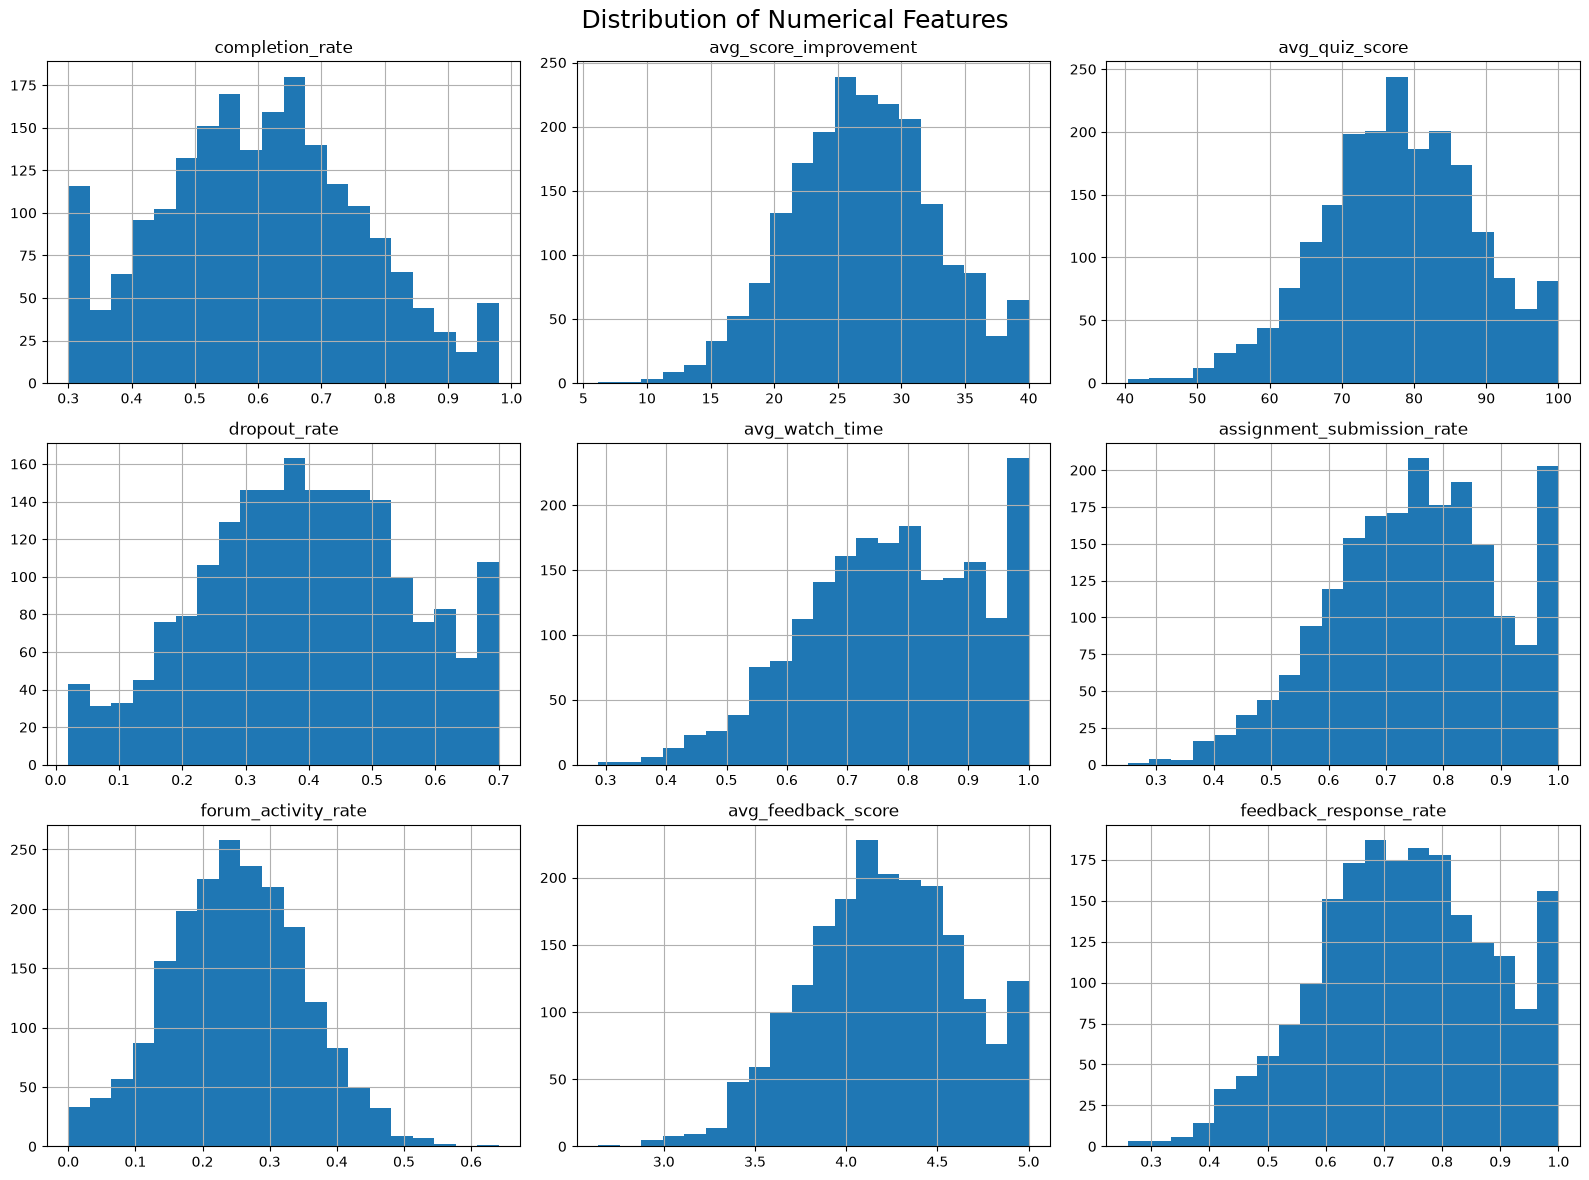

In [19]:
# Select numerical columns
numerical_cols = df.select_dtypes(include=['float64']).columns

# Plot histograms
df[numerical_cols].hist(figsize=(16, 12), bins=20)

plt.suptitle("Distribution of Numerical Features", fontsize=18)
plt.tight_layout()
plt.show()

### Observation

- Most numerical features exhibit approximately bell-shaped distributions with values concentrated around their means.
- Learner outcome metrics such as **completion rate**, **average score improvement**, and **average quiz score** show balanced distributions without extreme skewness.
- Engagement metrics including **average watch time**, **assignment submission rate**, and **feedback response rate** are concentrated toward higher values, indicating generally strong learner engagement.
- **Forum activity rate** has comparatively lower values than other engagement metrics, suggesting that discussion forum participation is relatively limited.
- No feature shows severe skewness or abnormal distributions that would immediately require transformation.

## Correlation Analysis

Correlation analysis helps identify relationships between numerical variables. It shows how strongly features move together and helps detect redundant features or important predictors for the machine learning model.

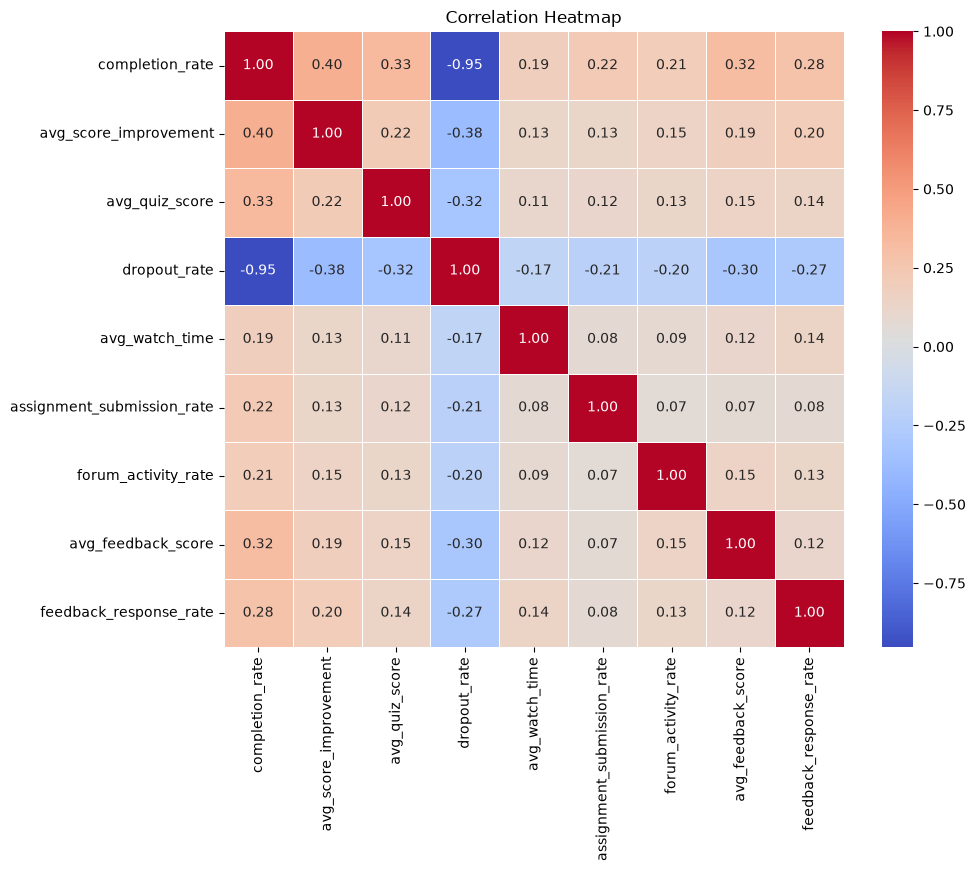

In [20]:
# Correlation Matrix
correlation_matrix = df[numerical_cols].corr()

# Plot Heatmap
plt.figure(figsize=(10,8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

### Observation

- Completion rate and dropout rate show a **very strong negative correlation (-0.95)**, indicating that batches with higher completion rates generally experience lower dropout rates.
- Completion rate has moderate positive correlations with average score improvement (0.40) and average quiz score (0.33), suggesting that better learner retention is associated with improved academic performance.
- Dropout rate exhibits negative correlations with most learner outcome, engagement, and feedback metrics, indicating that higher dropout is generally associated with poorer learning outcomes and learner satisfaction.
- Most remaining feature pairs show weak to moderate correlations, suggesting that they capture different aspects of instructor performance and are unlikely to introduce severe multicollinearity.

## Outlier Detection

Boxplots are used to identify potential outliers in numerical features. Understanding outliers helps determine whether additional preprocessing is required before feature engineering and model training.

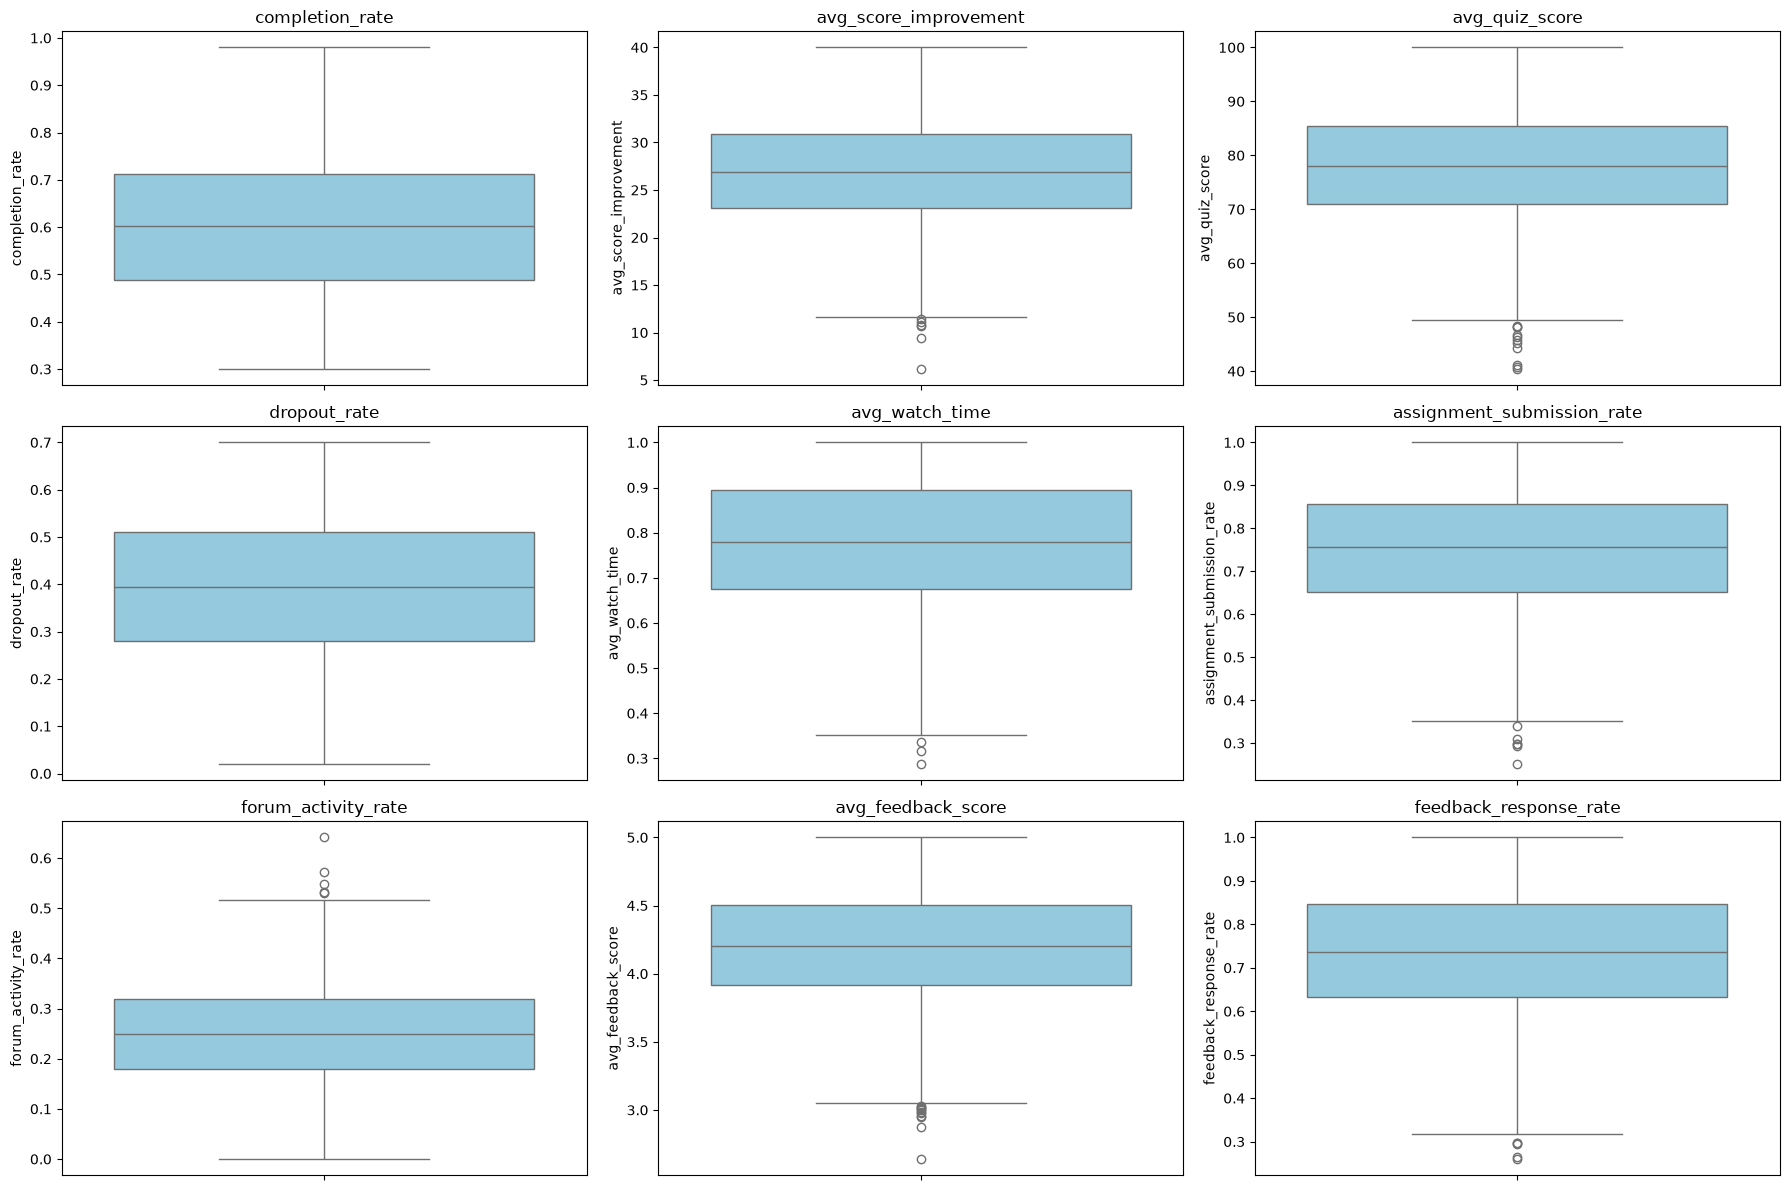

In [21]:
# Create boxplots for all numerical features

plt.figure(figsize=(18,12))

for i, column in enumerate(numerical_cols, 1):
    plt.subplot(3,3,i)
    sns.boxplot(y=df[column], color="skyblue")
    plt.title(column)

plt.tight_layout()
plt.show()

### Observation

- A small number of outliers are present in features such as average score improvement, average quiz score, average watch time, assignment submission rate, forum activity rate, average feedback score, and feedback response rate.
- These values appear to represent genuine variations in learner and instructor performance rather than data entry errors.
- Since the selected machine learning model (Random Forest) is relatively robust to outliers, no outlier removal was performed.

# Instructor-Level Aggregation

The original dataset contains one row per batch. Since the prediction target is instructor effectiveness, the dataset is aggregated to the instructor level. Mean aggregation is used for numerical performance metrics because it provides a representative measure of an instructor's overall teaching performance across multiple batches.

In [22]:
# Aggregate dataset to instructor level

instructor_df = (
    df.groupby("instructor_id")
      .agg({
          "completion_rate": "mean",
          "avg_score_improvement": "mean",
          "avg_quiz_score": "mean",
          "dropout_rate": "mean",
          "avg_watch_time": "mean",
          "assignment_submission_rate": "mean",
          "forum_activity_rate": "mean",
          "avg_feedback_score": "mean",
          "feedback_response_rate": "mean"
      })
      .reset_index()
)

# Display first few rows
instructor_df.head()

,instructor_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,I_001,0.543887,26.641462,78.900194,0.470593,0.766513,0.726893,0.240551,4.217743,0.694858
1,I_002,0.730874,30.166242,81.737198,0.247194,0.837393,0.774394,0.289610,4.343002,0.784338
2,I_003,0.768447,29.977813,81.590928,0.234828,0.818441,0.779606,0.296224,4.450034,0.812132
3,I_004,0.458328,22.912021,77.680317,0.547261,0.793130,0.758317,0.226259,4.076410,0.721460
4,I_005,0.859747,32.588652,85.828159,0.145733,0.847026,0.876942,0.333519,4.202516,0.784197


In [23]:
print(instructor_df.shape)

(120, 10)


# Feature Scaling and Instructor Effectiveness Score

The numerical performance metrics are measured on different scales. Min-Max Scaling is applied to ensure that all features contribute fairly to the composite effectiveness score.

To improve interpretability, three intermediate category scores are created:

- Learning Score
- Engagement Score
- Feedback Score

The final Instructor Effectiveness Score is calculated using weighted business assumptions, where learning outcomes receive the highest importance, followed by engagement and learner feedback. Dropout rate is treated as a penalty because it reflects learner disengagement.

In [25]:
# Create a copy of the aggregated dataset
scaled_df = instructor_df.copy()

# Features to normalize
features_to_scale = [
    "completion_rate",
    "avg_score_improvement",
    "avg_quiz_score",
    "dropout_rate",
    "avg_watch_time",
    "assignment_submission_rate",
    "forum_activity_rate",
    "avg_feedback_score",
    "feedback_response_rate"
]

# Apply Min-Max Scaling
scaler = MinMaxScaler()

scaled_df[features_to_scale] = scaler.fit_transform(
    scaled_df[features_to_scale]
)

scaled_df.head()

,instructor_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,I_001,0.367386,0.488597,0.571969,0.674863,0.447467,0.458320,0.525194,0.533079,0.348378
1,I_002,0.665425,0.708015,0.671737,0.299896,0.732860,0.588355,0.751970,0.670940,0.644331
2,I_003,0.725311,0.696286,0.666593,0.279139,0.656554,0.602625,0.782544,0.788738,0.736259
3,I_004,0.231012,0.256439,0.529071,0.803548,0.554639,0.544343,0.459130,0.377529,0.436363
4,I_005,0.870836,0.858811,0.815601,0.129597,0.771647,0.869081,0.954941,0.516321,0.643863


In [30]:
# Learning Outcome Score
scaled_df["learning_score"] = (
    scaled_df["completion_rate"] +
    scaled_df["avg_score_improvement"] +
    scaled_df["avg_quiz_score"]
) / 3

# Engagement Score
scaled_df["engagement_score"] = (
   0.40 * scaled_df["avg_watch_time"] +
   0.40 * scaled_df["assignment_submission_rate"] +
   0.20 * scaled_df["forum_activity_rate"]
) / 3

# Feedback Score
scaled_df["feedback_score"] = (
   0.70 * scaled_df["avg_feedback_score"] +
   0.30 * scaled_df["feedback_response_rate"]
) / 2

In [31]:
# Calculate Instructor Effectiveness Score

scaled_df["effectiveness_score"] = (
    0.40 * scaled_df["learning_score"] +
    0.30 * scaled_df["engagement_score"] +
    0.20 * scaled_df["feedback_score"] -
    0.10 * scaled_df["dropout_rate"]
)

In [32]:
scaled_df[
    [
        "instructor_id",
        "learning_score",
        "engagement_score",
        "feedback_score",
        "effectiveness_score"
    ]
].head()

,instructor_id,learning_score,engagement_score,feedback_score,effectiveness_score
0,I_001,0.475984,0.155785,0.238834,0.217410
1,I_002,0.681726,0.226293,0.331479,0.376884
2,I_003,0.696063,0.220060,0.386497,0.393829
3,I_004,0.338841,0.177140,0.197589,0.147841
4,I_005,0.848416,0.282426,0.277292,0.466593


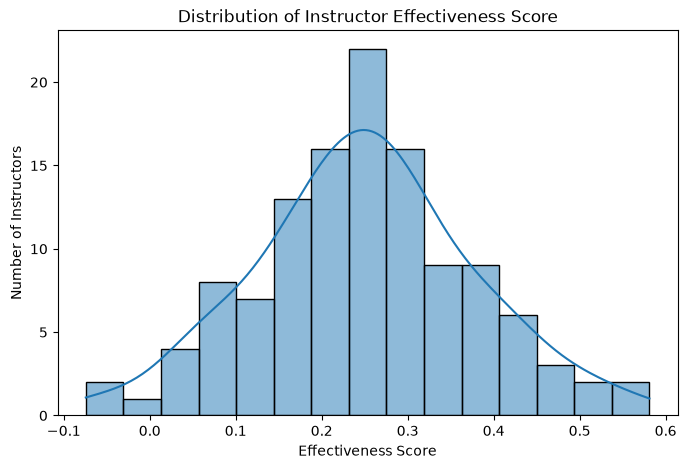

In [33]:
plt.figure(figsize=(8,5))

sns.histplot(
    scaled_df["effectiveness_score"],
    bins=15,
    kde=True
)

plt.title("Distribution of Instructor Effectiveness Score")
plt.xlabel("Effectiveness Score")
plt.ylabel("Number of Instructors")

plt.show()

In [34]:
# Check effectiveness score quantiles
scaled_df["effectiveness_score"].quantile([0, 0.33, 0.67, 1])

0.00   -0.074351
0.33    0.200848
0.67    0.299136
1.00    0.581152
Name: effectiveness_score, dtype: float64

In [35]:
# Create effectiveness categories
scaled_df["effectiveness_level"] = pd.qcut(
    scaled_df["effectiveness_score"],
    q=3,
    labels=["Low", "Medium", "High"]
)

scaled_df.head()

,instructor_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,learning_score,engagement_score,feedback_score,effectiveness_score,effectiveness_level
0,I_001,0.367386,0.488597,0.571969,0.674863,0.447467,0.458320,0.525194,0.533079,0.348378,0.475984,0.155785,0.238834,0.217410,Medium
1,I_002,0.665425,0.708015,0.671737,0.299896,0.732860,0.588355,0.751970,0.670940,0.644331,0.681726,0.226293,0.331479,0.376884,High
2,I_003,0.725311,0.696286,0.666593,0.279139,0.656554,0.602625,0.782544,0.788738,0.736259,0.696063,0.220060,0.386497,0.393829,High
3,I_004,0.231012,0.256439,0.529071,0.803548,0.554639,0.544343,0.459130,0.377529,0.436363,0.338841,0.177140,0.197589,0.147841,Low
4,I_005,0.870836,0.858811,0.815601,0.129597,0.771647,0.869081,0.954941,0.516321,0.643863,0.848416,0.282426,0.277292,0.466593,High


In [36]:
scaled_df["effectiveness_level"].value_counts()

effectiveness_level
Low       40
Medium    40
High      40
Name: count, dtype: int64

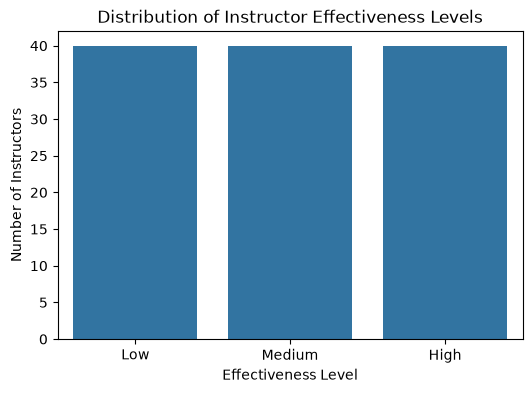

In [37]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=scaled_df,
    x="effectiveness_level",
    order=["Low", "Medium", "High"]
)

plt.title("Distribution of Instructor Effectiveness Levels")
plt.xlabel("Effectiveness Level")
plt.ylabel("Number of Instructors")

plt.show()

### Observation

The effectiveness scores were categorized into Low, Medium, and High using quantile-based binning. Each category contains 40 instructors, resulting in a balanced dataset for classification. Balanced class distributions help reduce bias during model training and improve the reliability of evaluation metrics.

# Machine Learning Model

The objective is to predict the Instructor Effectiveness Level (Low, Medium, High) using the original instructor performance metrics.

To avoid target leakage, engineered features such as Learning Score, Engagement Score, Feedback Score, and Effectiveness Score are excluded from model training because they were used to construct the target variable.

In [38]:
# Input features
X = scaled_df[
    [
        "completion_rate",
        "avg_score_improvement",
        "avg_quiz_score",
        "dropout_rate",
        "avg_watch_time",
        "assignment_submission_rate",
        "forum_activity_rate",
        "avg_feedback_score",
        "feedback_response_rate"
    ]
]

# Target variable
y = scaled_df["effectiveness_level"]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (120, 9)
Target Shape: (120,)


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 96
Testing samples: 24


In [40]:
# Initialize model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train model
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [41]:
# Predict on test data
y_pred = rf_model.predict(X_test)

In [42]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2%}")

Model Accuracy: 75.00%


In [43]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       0.75      0.75      0.75         8
         Low       1.00      0.75      0.86         8
      Medium       0.60      0.75      0.67         8

    accuracy                           0.75        24
   macro avg       0.78      0.75      0.76        24
weighted avg       0.78      0.75      0.76        24



<Figure size 600x500 with 0 Axes>

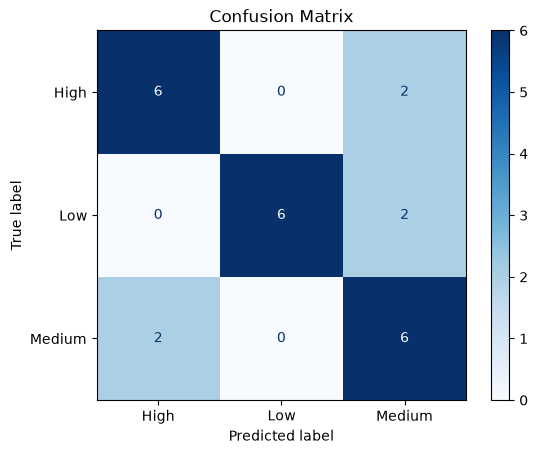

In [44]:
plt.figure(figsize=(6,5))

ConfusionMatrixDisplay.from_estimator(
    rf_model,
    X_test,
    y_test,
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.show()

### Observation

The Random Forest classifier achieved an accuracy of **75%** on the test dataset.

The confusion matrix shows that the model correctly classified most instructors across all three effectiveness levels. Misclassifications primarily occurred between the Medium and High classes, suggesting that instructors near the category boundaries share similar characteristics.

The model performed best for the Low effectiveness class with a precision of **1.00**, while the Medium class was comparatively more challenging to distinguish.

In [45]:
# Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,completion_rate,0.245678
3,dropout_rate,0.237414
8,feedback_response_rate,0.199081
1,avg_score_improvement,0.157159
2,avg_quiz_score,0.070827
7,avg_feedback_score,0.035509
4,avg_watch_time,0.024811
6,forum_activity_rate,0.023516
5,assignment_submission_rate,0.006005


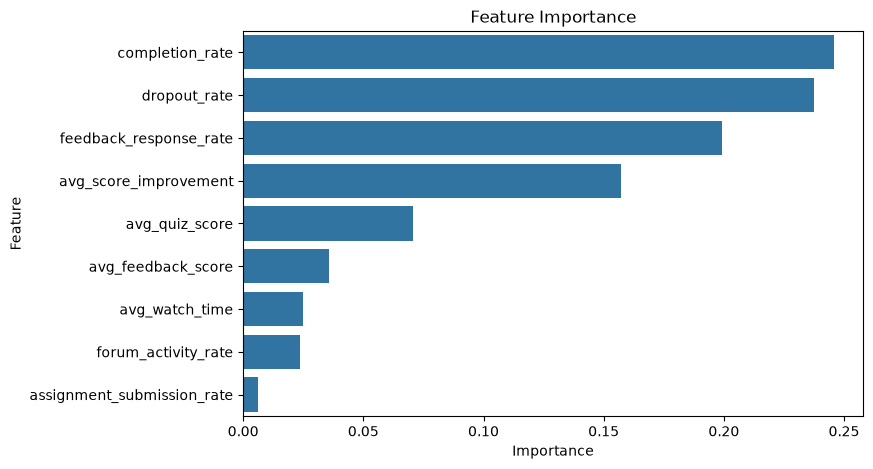

In [46]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")
plt.show()

### Observation

The Random Forest model identified **completion rate** and **dropout rate** as the most influential features for predicting instructor effectiveness. This aligns with the business objective, as learner retention is a strong indicator of teaching effectiveness.

Feedback response rate and average score improvement also contributed significantly to the model, while assignment submission rate, forum activity rate, and average watch time had comparatively lower importance.

These results suggest that learner retention and academic outcomes are stronger predictors of instructor effectiveness than individual engagement metrics.

# Conclusion

This project developed a machine learning framework to predict instructor effectiveness using learner performance, engagement, and feedback metrics.

### Key Findings

- The dataset was successfully transformed from batch-level records to instructor-level summaries.
- A weighted Instructor Effectiveness Score was designed using business-driven assumptions and normalized performance metrics.
- Random Forest achieved an accuracy of approximately **75%** in predicting instructor effectiveness levels.
- Completion Rate and Dropout Rate were identified as the most influential predictors of instructor effectiveness.
- The proposed framework demonstrates how educational platforms can evaluate instructors using multiple dimensions of learner outcomes and engagement.

### Future Improvements

- Collect real instructor effectiveness labels instead of generating labels from engineered scores.
- Experiment with additional machine learning models such as XGBoost and Gradient Boosting.
- Incorporate course difficulty, instructor experience, and learner demographics for improved predictive performance.
- Perform hyperparameter tuning and cross-validation to further improve model generalization.

## Limitations

- The Instructor Effectiveness Level was generated using an engineered scoring methodology rather than real-world labels.
- The selected feature weights were based on business assumptions and domain reasoning rather than expert-validated benchmarks.
- Course-specific characteristics and instructor experience were not included in the analysis.
- The model should be validated on real educational datasets before deployment in production environments.